# DX799 Week 6: Decision Trees and Random Forests
**Integrated Capstone Project:** VFX, Animation, and the Film Industry  
**Research question:** Can tuned decision trees and random forests improve worldwide movie revenue prediction compared with the Week 1 linear baseline? As an extension, can these algorithms classify the same 2x gross-to-budget outcome studied in Weeks 4 and 5?

This notebook uses the uploaded `movies.csv` and recreates the **same filtering, feature set, random seed, and 80/20 holdout assignment** used in earlier weeks. Figures, statistical results, and interpretive conclusions are generated from the data rather than assumed. The revenue task is primary, consistent with the user's Module B project. The classification extension connects to Weeks 4 and 5.

## 1. Concepts and evaluation plan
A decision tree recursively partitions the feature space. An unrestricted tree may memorize the training data. `max_depth`, `min_samples_leaf`, `min_samples_split`, and cost-complexity pruning constrain tree flexibility. A random forest averages predictions from many bootstrapped trees and introduces randomness through feature subsampling, generally reducing variance. `n_estimators` controls the number of trees; `max_features` controls predictors considered at each split.

**Evaluation safeguards:** Reserve the original 20% test sample; tune only on five-fold training cross-validation; compare against an identical linear regression baseline; report test R², RMSE, and MAE. For classification, optimize CV ROC-AUC, then report held-out ROC-AUC, F1, accuracy, precision, and recall. We separately report training error to diagnose overfitting. The random split measures generalization within this observed sample, not future-release forecasting. No post-release votes, ratings, or popularity are predictors.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, confusion_matrix,
                             RocCurveDisplay)
from sklearn.inspection import permutation_importance
SEED=42
path=Path('movies.csv')
if not path.exists():path=Path('/mnt/data/movies.csv')
raw=pd.read_csv(path)
print('Source:',path,'| rows:',len(raw),'| columns:',len(raw.columns))

Source: movies.csv | rows: 18905 | columns: 23


## 2. Data cleaning and Week 1 consistency
Require positive recorded budget and revenue, a valid date, release year 1980 through 2024, and runtime 40 through 240 minutes. This is a **financial-reporting subset** rather than a representative sample of all films. Parse multi-label genres into binary indicators. Use January as the reference month and retain the same 19 Week 1 controls. Revenue is measured in millions of reported dollars, not inflation-adjusted.

In [2]:
df=raw.drop_duplicates(subset=['movie_id']).copy()
df['release_date']=pd.to_datetime(df['release_date'],errors='coerce')
for col in ['budget','revenue','runtime','release_year']:
    df[col]=pd.to_numeric(df[col],errors='coerce')
df=df.loc[(df.budget>0)&(df.revenue>0)&df.release_year.between(1980,2024)&df.runtime.between(40,240)&df.release_date.notna()].copy()
df['budget_m']=df.budget/1e6
df['revenue_m']=df.revenue/1e6
parsed=df.genres.fillna('').str.split('|')
df['animation']=parsed.map(lambda g:int('Animation' in g))
for genre in ['Action','Comedy','Drama','Horror']:
    df['genre_'+genre.lower()]=parsed.map(lambda g:int(genre in g))
df['release_month']=df.release_date.dt.month
for month in range(2,13):df[f'month_{month}']=(df.release_month==month).astype(int)
features=['budget_m','runtime','release_year','animation','genre_action','genre_comedy','genre_drama','genre_horror']+[f'month_{i}' for i in range(2,13)]
tr,te=train_test_split(np.arange(len(df)),test_size=.2,random_state=SEED)
train,test=df.iloc[tr].copy(),df.iloc[te].copy()
X_train,X_test=train[features],test[features]
y_train,y_test=train.revenue_m,test.revenue_m
print(f'Filtered sample: {len(df):,}; training: {len(train):,}; test: {len(test):,}; features: {len(features)}')
print(f'Animation movies: {int(df.animation.sum()):,}')
print(df[['budget_m','revenue_m','runtime']].describe(percentiles=[.5,.9,.99]).round(2).to_string())

Filtered sample: 7,079; training: 5,663; test: 1,416; features: 19
Animation movies: 376
       budget_m  revenue_m  runtime
count   7079.00    7079.00  7079.00
mean      33.54      90.64   106.89
std       43.70     181.95    17.75
min        0.00       0.00    56.00
50%       19.00      26.81   104.00
90%       80.00     233.96   130.00
99%      200.00     921.46   165.00
max      658.80    2923.71   229.00


## 3. EDA: Budget, revenue, and outliers
Movie revenues are heavily right-skewed, with a few exceptionally large releases. Because RMSE squares errors, these outliers can disproportionately affect model comparisons. We keep outcomes on the original dollar scale so comparison with prior weeks is straightforward.

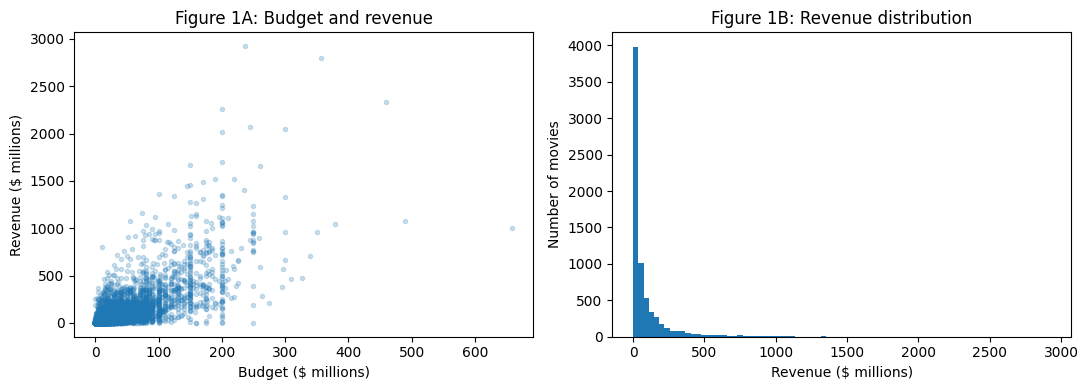

Pearson budget/revenue correlation: 0.726


In [3]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].scatter(df.budget_m,df.revenue_m,s=9,alpha=.22)
axs[0].set(xlabel='Budget ($ millions)',ylabel='Revenue ($ millions)',title='Figure 1A: Budget and revenue')
axs[1].hist(df.revenue_m,bins=80)
axs[1].set(xlabel='Revenue ($ millions)',ylabel='Number of movies',title='Figure 1B: Revenue distribution')
plt.tight_layout();plt.show()
print('Pearson budget/revenue correlation:',round(df[['budget_m','revenue_m']].corr().iloc[0,1],3))

## 4. Establish the Week 1 linear regression baseline
Use the 19-feature control specification, without polynomial or interaction terms. This provides a directly comparable reference. Models are evaluated on the same holdout test rows.

In [4]:
linear=LinearRegression().fit(X_train,y_train)
def reg_metrics(label,model):
    ptr=model.predict(X_train); pte=model.predict(X_test)
    return {'Model':label,'Train R2':r2_score(y_train,ptr),'Test R2':r2_score(y_test,pte),
            'Train RMSE ($M)':np.sqrt(mean_squared_error(y_train,ptr)),
            'Test RMSE ($M)':np.sqrt(mean_squared_error(y_test,pte)),
            'Test MAE ($M)':mean_absolute_error(y_test,pte)}
print(pd.DataFrame([reg_metrics('OLS baseline',linear)]).round(3).to_string(index=False))

       Model  Train R2  Test R2  Train RMSE ($M)  Test RMSE ($M)  Test MAE ($M)
OLS baseline     0.545    0.514          125.937         112.443         63.953


## 5. Regression hyperparameter tuning
We tune shallow-to-moderate trees and random forests with **five-fold KFold CV on the training subset**. For efficient peer review, randomized search tests a reproducible sample of combinations. Selection maximizes negative RMSE, which corresponds to minimizing CV RMSE. We do not search the reserved test data. For forests, the training-fold CV tests how well bagging and split restrictions reduce overfitting.

In [5]:
cv=KFold(n_splits=5,shuffle=True,random_state=SEED)
reg_configs={
  'Decision Tree':(DecisionTreeRegressor(random_state=SEED),{
      'max_depth':[3,5,8,12,18,None], 'min_samples_leaf':[2,5,10,20,40],
      'min_samples_split':[2,10,25,50], 'ccp_alpha':[0.,1.,10.,100.]}),
  'Random Forest':(RandomForestRegressor(random_state=SEED,n_jobs=1),{
      'n_estimators':[60,100], 'max_depth':[6,10,16,None],
      'min_samples_leaf':[1,3,7,15], 'max_features':[.5,.8,1.0]})
}
reg_searches={};reg_models={}
for name,(est,params) in reg_configs.items():
    n_iter=8 if name=='Decision Tree' else 5
    search=RandomizedSearchCV(est,params,n_iter=n_iter,scoring='neg_root_mean_squared_error',
                              cv=cv,n_jobs=2,random_state=SEED,refit=True)
    search.fit(X_train,y_train)
    reg_searches[name]=search;reg_models[name]=search.best_estimator_
    print(f'{name}: CV RMSE=${-search.best_score_:.3f}M | {search.best_params_}')

Decision Tree: CV RMSE=$128.630M | {'min_samples_split': 2, 'min_samples_leaf': 10, 'max_depth': 5, 'ccp_alpha': 10.0}


Random Forest: CV RMSE=$123.348M | {'n_estimators': 100, 'min_samples_leaf': 7, 'max_features': 0.5, 'max_depth': None}


## 6. Compare train/test performance and model complexity
A large gap between training and test accuracy suggests overfitting. A smaller gap does not establish that the model is optimal: both bias and sample limitations matter. A random forest's averaged trees may reduce overfitting relative to a single tree. Interpret R² against the held-out sample only.

               Train R2  Test R2  Train RMSE ($M)  Test RMSE ($M)  Test MAE ($M)
Model                                                                           
OLS baseline      0.545    0.514          125.937         112.443         63.953
Decision Tree     0.614    0.443          116.059         120.375         61.815
Random Forest     0.681    0.565          105.507         106.388         56.733


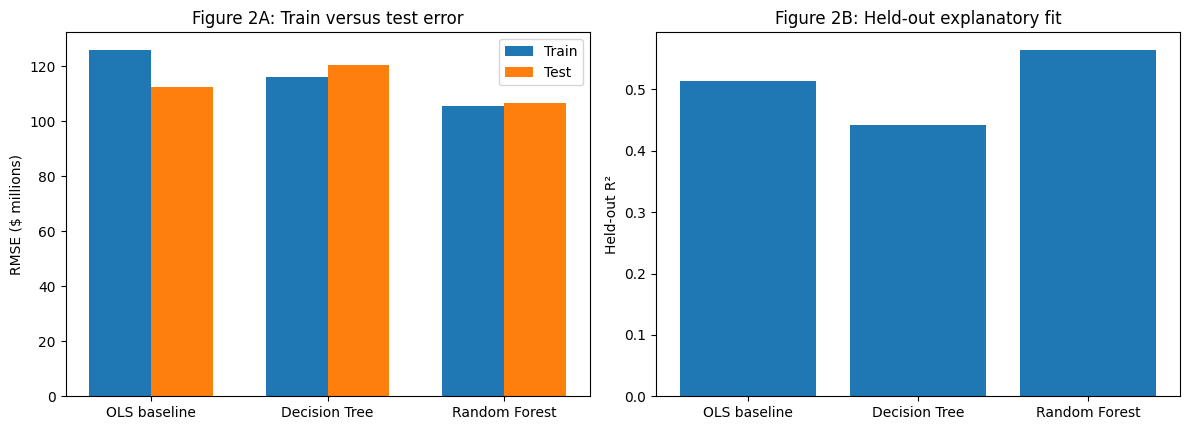

In [6]:
reg_results=pd.DataFrame([reg_metrics('OLS baseline',linear)]+[reg_metrics(name,model) for name,model in reg_models.items()]).set_index('Model')
print(reg_results.round(3).to_string())
fig,axs=plt.subplots(1,2,figsize=(12,4.4))
x=np.arange(len(reg_results));w=.35
axs[0].bar(x-w/2,reg_results['Train RMSE ($M)'],width=w,label='Train')
axs[0].bar(x+w/2,reg_results['Test RMSE ($M)'],width=w,label='Test')
axs[0].set(xticks=x,xticklabels=reg_results.index,ylabel='RMSE ($ millions)',title='Figure 2A: Train versus test error')
axs[0].legend()
axs[1].bar(reg_results.index,reg_results['Test R2'])
axs[1].set(ylabel='Held-out R²',title='Figure 2B: Held-out explanatory fit')
plt.tight_layout();plt.show()

## 7. Inspect how trees make decisions
Visualizing the top levels of a tuned decision tree highlights splits, while keeping the plot legible. Splits are predictive associations, not evidence that changing a budget would cause revenue to rise. A deep tree may be too complex to interpret in full.

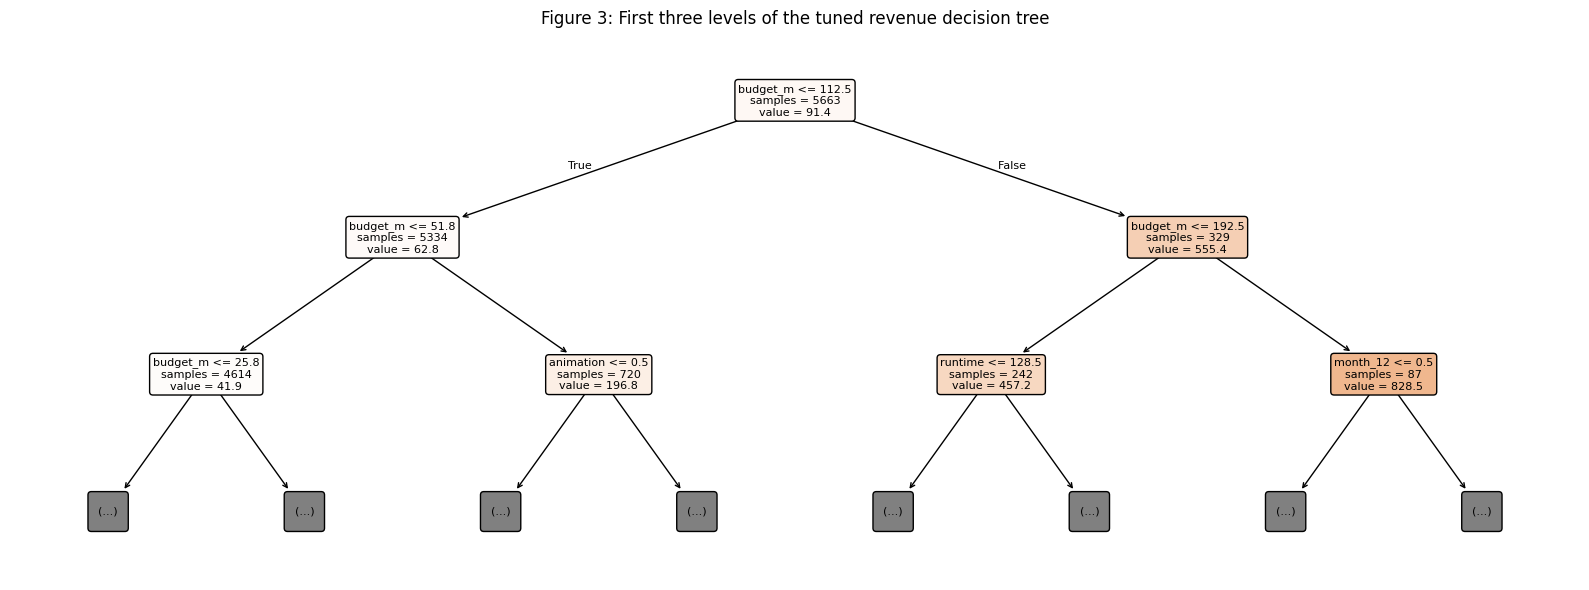

In [7]:
fig,ax=plt.subplots(figsize=(16,6))
plot_tree(reg_models['Decision Tree'],feature_names=features,max_depth=2,filled=True,rounded=True,
          fontsize=8,ax=ax,impurity=False,precision=1)
ax.set_title('Figure 3: First three levels of the tuned revenue decision tree')
plt.tight_layout();plt.show()

## 8. Random forest permutation importance
Permutation importance measures how much held-out model error rises when one feature is shuffled. Unlike impurity-based importance, this is tied to test-set predictive impact, although it can still be affected by correlated variables and random variability. This exploratory test-set diagnostic must **not** be used for model selection or retuning.

Permutation importance: increase in RMSE ($M) when shuffled
budget_m        68.116
genre_drama     -4.744
runtime         -5.737
month_4         -6.903
genre_action    -7.984
release_year    -8.017
month_7         -8.533
genre_horror    -8.582
genre_comedy    -8.668
month_8         -8.680


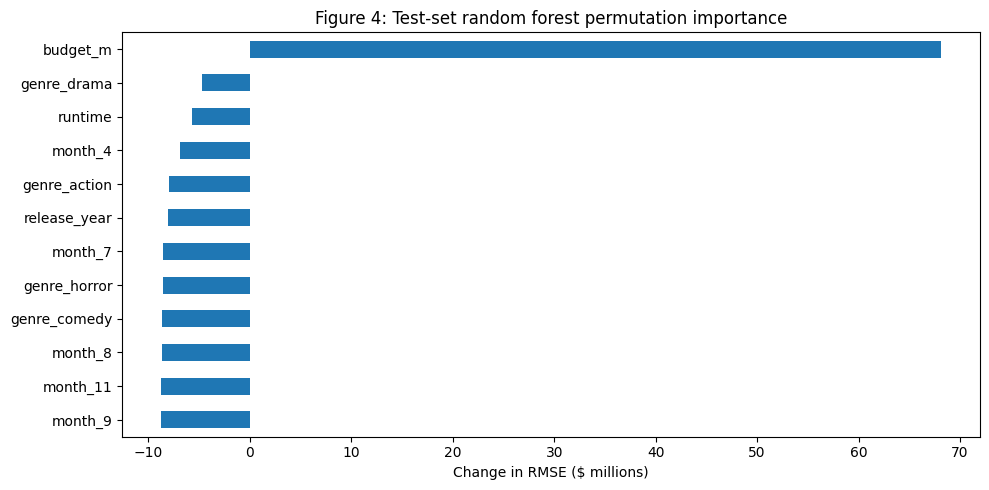

In [8]:
forest=reg_models['Random Forest']
perm=permutation_importance(forest,X_test,y_test,n_repeats=2,random_state=SEED,
                            scoring='neg_root_mean_squared_error',n_jobs=1,max_samples=400)
importance=pd.Series(perm.importances_mean,index=features).sort_values(ascending=False)
print('Permutation importance: increase in RMSE ($M) when shuffled')
print(importance.head(10).round(3).to_string())
fig,ax=plt.subplots(figsize=(10,5))
importance.head(12).sort_values().plot.barh(ax=ax)
ax.set(xlabel='Change in RMSE ($ millions)',title='Figure 4: Test-set random forest permutation importance')
plt.tight_layout();plt.show()

## 9. Revenue prediction errors
Actual-versus-predicted plots show whether the model systematically misses the largest grossing movies. Residuals are calculated as actual minus predicted revenue. Individual blockbusters can dominate RMSE, so MAE is also informative.

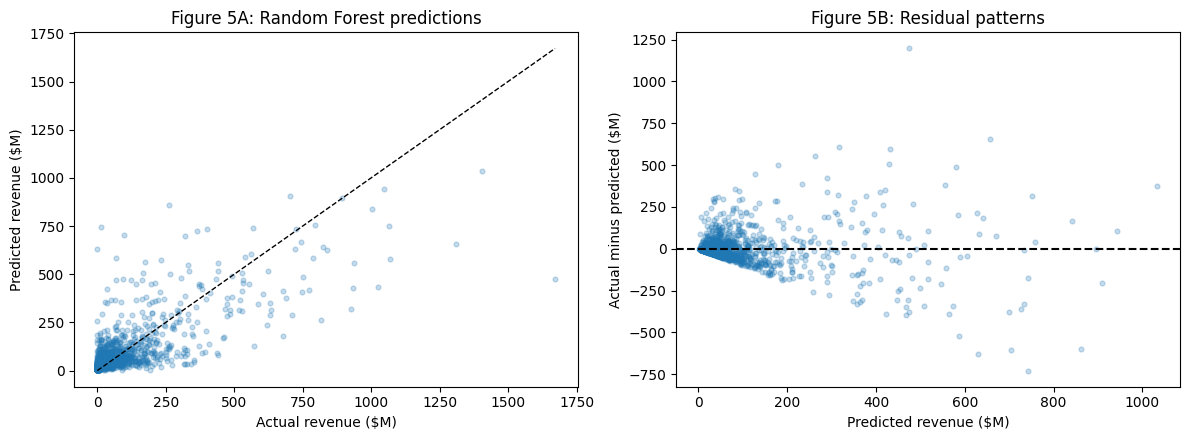

In [9]:
best_reg_name=min(reg_searches,key=lambda name:-reg_searches[name].best_score_)
best_reg=reg_models[best_reg_name]
pred=best_reg.predict(X_test)
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
axs[0].scatter(y_test,pred,alpha=.25,s=12)
bounds=[min(y_test.min(),pred.min()),max(y_test.max(),pred.max())]
axs[0].plot(bounds,bounds,'k--',linewidth=1)
axs[0].set(xlabel='Actual revenue ($M)',ylabel='Predicted revenue ($M)',title=f'Figure 5A: {best_reg_name} predictions')
axs[1].scatter(pred,y_test-pred,alpha=.25,s=12)
axs[1].axhline(0,color='black',linestyle='--')
axs[1].set(xlabel='Predicted revenue ($M)',ylabel='Actual minus predicted ($M)',title='Figure 5B: Residual patterns')
plt.tight_layout();plt.show()

## 10. Classification extension: Tie Weeks 4 and 5 together
Define `success = 1` if reported worldwide revenue is at least **twice** reported production budget. As before, this is a gross-to-budget indicator, **not profitability**, because marketing, distribution, and revenue sharing are excluded. The same 19 input variables are used; in particular, revenue is not an input. The 2x classification target embeds budget in its denominator, so its budget relationships require caution. Five-fold **stratified** CV selects a pruned decision tree and a random forest based on ROC-AUC. We also fit a scaled logistic baseline for continuity with Week 4.

In [10]:
train['success']=(train.revenue/train.budget>=2).astype(int)
test['success']=(test.revenue/test.budget>=2).astype(int)
yc_train,yc_test=train.success,test.success
scv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
clf_configs={
 'Decision Tree Classifier':(DecisionTreeClassifier(random_state=SEED),{
   'max_depth':[3,5,8,12,None], 'min_samples_leaf':[5,10,20,40], 'ccp_alpha':[0.,.001,.005,.01]}),
 'Random Forest Classifier':(RandomForestClassifier(random_state=SEED,n_jobs=1),{
   'n_estimators':[60,100], 'max_depth':[5,10,None], 'min_samples_leaf':[2,5,10], 'max_features':['sqrt',.8]})}
clf_searches={};clf_models={}
for name,(model,params) in clf_configs.items():
    s=RandomizedSearchCV(model,params,n_iter=5,scoring='roc_auc',cv=scv,n_jobs=2,random_state=SEED)
    s.fit(X_train,yc_train);clf_searches[name]=s;clf_models[name]=s.best_estimator_
    print(name,'CV ROC-AUC:',round(s.best_score_,4),'parameters:',s.best_params_)
from sklearn.model_selection import GridSearchCV
logsearch=GridSearchCV(Pipeline([('scale',StandardScaler()),('log',LogisticRegression(max_iter=6000,solver='liblinear',random_state=SEED))]),
                       {'log__C':[.001,.01,.1,1,10,100]},scoring='roc_auc',cv=scv,n_jobs=2)
logsearch.fit(X_train,yc_train)
clf_models={'Scaled Logistic baseline':logsearch.best_estimator_,**clf_models}
def classify_metrics(name,model):
    prob=model.predict_proba(X_test)[:,1];p=model.predict(X_test)
    return {'Model':name,'ROC-AUC':roc_auc_score(yc_test,prob),'Accuracy':accuracy_score(yc_test,p),
            'Precision':precision_score(yc_test,p,zero_division=0),'Recall':recall_score(yc_test,p,zero_division=0),
            'F1':f1_score(yc_test,p,zero_division=0)}
clf_results=pd.DataFrame([classify_metrics(n,m) for n,m in clf_models.items()]).set_index('Model')
print('Holdout classification results:')
print(clf_results.round(4).to_string())

Decision Tree Classifier CV ROC-AUC: 0.6103 parameters: {'min_samples_leaf': 20, 'max_depth': None, 'ccp_alpha': 0.0}


Random Forest Classifier CV ROC-AUC: 0.6617 parameters: {'n_estimators': 100, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 10}


Holdout classification results:
                          ROC-AUC  Accuracy  Precision  Recall      F1
Model                                                                 
Scaled Logistic baseline   0.6137    0.5911     0.5432  0.3290  0.4098
Decision Tree Classifier   0.6199    0.6024     0.5488  0.4419  0.4896
Random Forest Classifier   0.6505    0.6208     0.6076  0.3421  0.4377


## 11. Classification ROC curves and confusion matrix
ROC-AUC summarizes discrimination across thresholds; F1 describes a single threshold. The forest or tree with the highest **training CV ROC-AUC** is the preselected tree-based classifier, regardless of which scores highest on the test set. ROC-AUC results cannot be numerically compared to regression R².

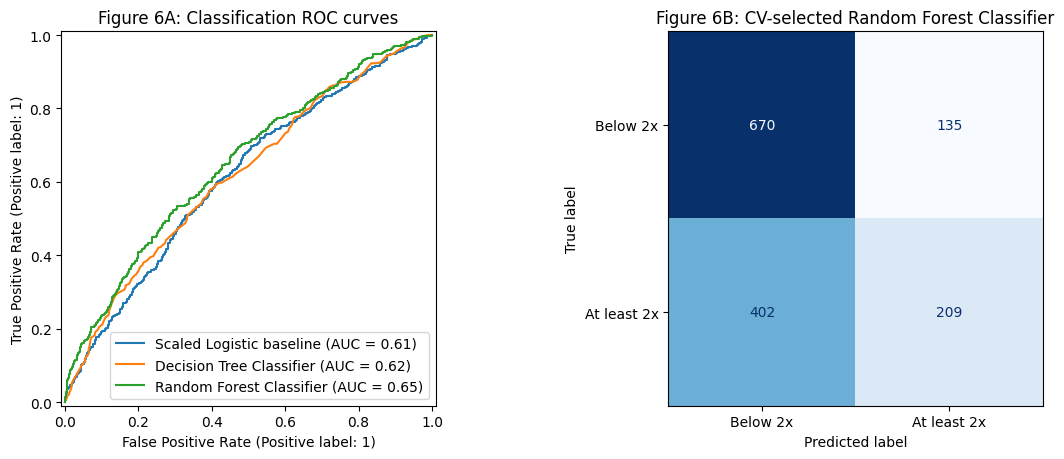

In [11]:
fig,axs=plt.subplots(1,2,figsize=(12,4.7))
for name,model in clf_models.items():
    RocCurveDisplay.from_estimator(model,X_test,yc_test,ax=axs[0],name=name)
axs[0].set_title('Figure 6A: Classification ROC curves')
best_clf_name=max(clf_searches,key=lambda name:clf_searches[name].best_score_)
best_clf=clf_models[best_clf_name]
ConfusionMatrixDisplay(confusion_matrix(yc_test,best_clf.predict(X_test),labels=[0,1]),
                       display_labels=['Below 2x','At least 2x']).plot(ax=axs[1],cmap='Blues',colorbar=False)
axs[1].set_title(f'Figure 6B: CV-selected {best_clf_name}')
plt.tight_layout();plt.show()

## 12. Conclusions for the Milestone One report
Review generated results below when writing Week 7. There are separate questions: (a) predicting the numerical gross of a movie and (b) classifying whether gross is at least 2x budget. Random forests typically capture nonlinearities and interactions automatically, but this dataset's actual results determine whether they improve accuracy. CV scores guide selection; held-out scores estimate generalization. The source dataset includes only films with reported positive budgets and revenues, and financial quantities are not inflation-adjusted. A future study should use chronological validation and assess external predictor availability before release.

In [12]:
print('REGRESSION:')
print(reg_results.round(3).to_string())
print('Model with lowest training CV RMSE:',best_reg_name)
for name in ['Decision Tree','Random Forest']:
    row=reg_results.loc[name]
    print(f'{name}: test R²={row["Test R2"]:.3f}; RMSE=${row["Test RMSE ($M)"]:.2f}M; train-test RMSE gap=${row["Test RMSE ($M)"]-row["Train RMSE ($M)"]:.2f}M')
print('CLASSIFICATION:')
print(clf_results.round(3).to_string())
print('Preselected tree classifier by train CV:',best_clf_name)
print('Best-regression RMSE improvement vs OLS ($M):',round(reg_results.loc['OLS baseline','Test RMSE ($M)']-reg_results.loc[best_reg_name,'Test RMSE ($M)'],3))

REGRESSION:
               Train R2  Test R2  Train RMSE ($M)  Test RMSE ($M)  Test MAE ($M)
Model                                                                           
OLS baseline      0.545    0.514          125.937         112.443         63.953
Decision Tree     0.614    0.443          116.059         120.375         61.815
Random Forest     0.681    0.565          105.507         106.388         56.733
Model with lowest training CV RMSE: Random Forest
Decision Tree: test R²=0.443; RMSE=$120.38M; train-test RMSE gap=$4.32M
Random Forest: test R²=0.565; RMSE=$106.39M; train-test RMSE gap=$0.88M
CLASSIFICATION:
                          ROC-AUC  Accuracy  Precision  Recall     F1
Model                                                                
Scaled Logistic baseline    0.614     0.591      0.543   0.329  0.410
Decision Tree Classifier    0.620     0.602      0.549   0.442  0.490
Random Forest Classifier    0.651     0.621      0.608   0.342  0.438
Preselected tree classi

## References and AI usage appendix
- Boston University DX799: Week 6 Decision Trees and Random Forests, and Milestone One Guidelines and Rubric.
- [scikit-learn: Decision Trees](https://scikit-learn.org/stable/modules/tree.html)
- [scikit-learn: Random Forests](https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees)
- [scikit-learn: RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)
- [scikit-learn: permutation_importance](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html)
- Source: `movies.csv`, the TMDb-derived film dataset supplied for this Capstone.

**AI disclosure:** ChatGPT helped construct the notebook, code, analysis workflow, and writing. All reported quantitative metrics are calculated by executing the notebook on the uploaded dataset. The author should verify outputs and follow the course's AI disclosure policy.